In [ ]:
# 준비된 기존 데이터를 참고하여, 아래 문제들을 하나씩 해결하여라.

# 문제 1. 이동 거리와 요금 데이터를 학습용 데이터와 테스트용 데이터로 분리하시오.
# 문제 2. 선형 회귀 모델을 생성하고 학습시키시오.
# 문제 3. 모델의 성능 점수와 평균 절대 오차를 출력하시오.
# 문제 4. 택시로 7.5km 이동할 경우 예상 요금을 출력하시오.
# 문제 5. 예산이 20,000원일 때 최대 몇 km까지 이동할 수 있는지 구하시오.
# 문제 6. 실제 요금 데이터와 예측 요금을 그래프로 표현하시오.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error

In [2]:
# 과거 데이터 준비
dist = np.array([1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 12, 15])        # 이동거리(km)
fare = np.array([5000, 6100, 7300, 8400, 9600, 10700, 11900, 13000, 14200, 15300, 17600, 21100])    # 택시 요금(원)

In [10]:
# 1. dist와 fare를 학습용 데이터와 테스트용 데이터로 분리하시오.

# train_test_split() :: 원본 배열(dist, fare)을 학습용/테스트용 "무작위/고정" 선택해서 분리
#   => 학습용 x, 테스트용 x / 학습용 y, 테스트용 y
x_train, x_test, y_train, y_test = train_test_split(
    dist.reshape(-1, 1),       # 영향을 주는 요인(x)
    fare,                      # 영향을 받는 결과(y)
    test_size = 0.4,    # 40%를 테스트 데이터 선택
    random_state = 42   # 테스트 데이터 고정 선택
)

print(x_test)
print(y_test)

# dist = x_train + x_test
# fare = y_train + y_test

[[12]
 [10]
 [ 1]
 [ 9]
 [ 6]]
[17600 15300  5000 14200 10700]


In [12]:
# 2. 선형 회귀 모델을 생성하고 학습시키시오.
model = LinearRegression()
model.fit(x_train, y_train)     # 학습용 데이터(train)로 학습 진행

LinearRegression()

In [22]:
# 3. 모델의 성능 점수와 평균 절대 오차를 출력하시오.

# score(테스트용_문제(x), 테스트용_정답(y)) ::
#       머신러닝 모델 평가 ("얼마나 잘 예측하는가")
result = model.score(x_test, y_test)
print('성능 점수:', result)

# mean_absolute_error(실제 정답(y), 모델이 예측한 값) ::
#       머신러닝 모델 평균 오차 구하기 ("어느정도의 오차를 범하는가")

pred = model.predict(x_test)
error = mean_absolute_error(y_test, pred)
print('평균 오차값:', error)

성능 점수: 0.999947400672969
평균 오차값: 30.64356435643531


In [24]:
# [참고] 오차값이란
print('[문제 양식] 이동하는 거리가 00km 일 때, 택시 비용은 얼마인가?')
print('1번 문제:', x_test[0])
print('2번 문제:', x_test[1])
print('3번 문제:', x_test[2])
print('4번 문제:', x_test[3])
print('5번 문제:', x_test[4])
print()

print('[머신러닝이 제시한 답]')
print('1번 문제의 답:', model.predict([x_test[0]]))
print('2번 문제의 답:', model.predict([x_test[1]]))
print('3번 문제의 답:', model.predict([x_test[2]]))
print('4번 문제의 답:', model.predict([x_test[3]]))
print('5번 문제의 답:', model.predict([x_test[4]]))
print()

print('[문제에 대한 정답]')
print('1번 문제 정답:', y_test[0])
print('2번 문제 정답:', y_test[1])
print('3번 문제 정답:', y_test[2])
print('4번 문제 정답:', y_test[3])
print('5번 문제 정답:', y_test[4])
print()

print('[머신러닝의 답 - 문제의 정답] 간의 차이')
print('1번 문제:', abs(model.predict([x_test[0]]) - y_test[0]))
print('2번 문제:', abs(model.predict([x_test[1]]) - y_test[1]))
print('3번 문제:', abs(model.predict([x_test[2]]) - y_test[2]))
print('4번 문제:', abs(model.predict([x_test[3]]) - y_test[3]))
print('5번 문제:', abs(model.predict([x_test[4]]) - y_test[4]))

# 위 값들을 합하고, 문제 수(5)만큼 나눈다
#     => mean_absolute_error() 결과값

[문제 양식] 이동하는 거리가 00km 일 때, 택시 비용은 얼마인가?
1번 문제: [12]
2번 문제: [10]
3번 문제: [1]
4번 문제: [9]
5번 문제: [6]

[머신러닝이 제시한 답]
1번 문제의 답: [17640.59405941]
2번 문제의 답: [15336.38613861]
3번 문제의 답: [4967.45049505]
4번 문제의 답: [14184.28217822]
5번 문제의 답: [10727.97029703]

[문제에 대한 정답]
1번 문제 정답: 17600
2번 문제 정답: 15300
3번 문제 정답: 5000
4번 문제 정답: 14200
5번 문제 정답: 10700

[머신러닝의 답 - 문제의 정답] 간의 차이
1번 문제: [40.59405941]
2번 문제: [36.38613861]
3번 문제: [32.54950495]
4번 문제: [15.71782178]
5번 문제: [27.97029703]


In [25]:
# 4. 택시로 7.5km 이동할 경우 예상 요금을 출력하시오.
result = model.predict([[7.5]])
print('예상 요금:', result, '원')

# 7km 실제 요금 :: 11900원
# 8km 실제 요금 :: 13000원

예상 요금: [12456.12623762] 원


In [27]:
# 5. 예산이 20,000원일 때 최대 몇 km까지 이동할 수 있는지 구하시오.

test_dist = np.arange(0, 16, 1)     # [1, 2, 3, ..., 14, 15]

max_dist = 0
for i in test_dist:     # i = 1 ~ 15
  result = model.predict([[i]])  # 1~15km의 비용 각각 예측

  if result <= 20000:
    max_dist = i
    print(max_dist, result)     # max_dist 값이 변동
print('최대 이동 거리:', max_dist)

0 [3815.34653465]
1 [4967.45049505]
2 [6119.55445545]
3 [7271.65841584]
4 [8423.76237624]
5 [9575.86633663]
6 [10727.97029703]
7 [11880.07425743]
8 [13032.17821782]
9 [14184.28217822]
10 [15336.38613861]
11 [16488.49009901]
12 [17640.59405941]
13 [18792.6980198]
14 [19944.8019802]
최대 이동 거리: 14


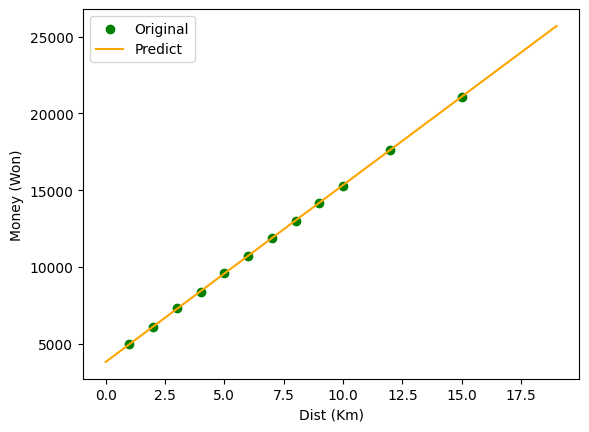

In [28]:
# 6. 실제 요금 데이터와 예측 요금을 그래프로 표현하시오.

# 실제 데이터 - 점 그래프
plt.scatter(dist, fare, color='green', label='Original')

# 예측 데이터 - 선 그래프
test_dist = np.arange(0, 20, 1)
pred_fare = model.predict(test_dist.reshape(-1, 1))    # 0~19km 각각의 택시 비용 예측
plt.plot(test_dist, pred_fare, color='orange', label='Predict')

plt.xlabel('Dist (Km)')
plt.ylabel('Money (Won)')
plt.legend()
plt.show()